In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("fifadata.csv")
print(df.head())

          short_name player_positions    value_eur  wage_eur  age  \
0           L. Messi               CF  100500000.0  550000.0   27   
1  Cristiano Ronaldo           LW, LM   79000000.0  375000.0   29   
2          A. Robben       RM, LM, RW   54500000.0  275000.0   30   
3    Z. Ibrahimovi€à               ST   52500000.0  275000.0   32   
4           M. Neuer               GK   63500000.0  300000.0   28   

             club_name nationality_name  
0         FC Barcelona        Argentina  
1       Real Madrid CF         Portugal  
2   FC Bayern MÌ?nchen      Netherlands  
3  Paris Saint-Germain           Sweden  
4   FC Bayern MÌ?nchen          Germany  


In [3]:
print(df.shape)

(169, 7)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169 entries, 0 to 168
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   short_name        169 non-null    object 
 1   player_positions  169 non-null    object 
 2   value_eur         163 non-null    float64
 3   wage_eur          164 non-null    float64
 4   age               169 non-null    int64  
 5   club_name         168 non-null    object 
 6   nationality_name  169 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 9.4+ KB


In [5]:
print(df.describe())

          value_eur       wage_eur         age
count  1.630000e+02     164.000000  169.000000
mean   2.028098e+07  150945.121951   27.869822
std    1.353299e+07   57925.724924    3.299654
min    1.300000e+06   50000.000000   21.000000
25%    1.250000e+07  120000.000000   26.000000
50%    1.600000e+07  140000.000000   28.000000
75%    2.300000e+07  170000.000000   30.000000
max    1.005000e+08  550000.000000   36.000000


In [6]:
numeric_columns = ['value_eur', 'wage_eur', 'age']
categorical_columns = ['short_name', 'player_positions', 'club_name', 'nationality_name']
print(numeric_columns)
print(categorical_columns)

['value_eur', 'wage_eur', 'age']
['short_name', 'player_positions', 'club_name', 'nationality_name']


In [7]:
print(df.isna().sum())
df = df.dropna(subset=['value_eur', 'wage_eur', 'age', 'player_positions']).copy()

short_name          0
player_positions    0
value_eur           6
wage_eur            5
age                 0
club_name           1
nationality_name    0
dtype: int64


In [8]:
df['value_million'] = df['value_eur'].apply(lambda x: x / 1000000)

In [9]:
def classify_age(age):
    if age < 23:
        return 'Young'
    elif age < 30:
        return 'Prime'
    else:
        return 'Veteran'

df['age_group'] = df['age'].apply(classify_age)

In [10]:
print(df.head())

          short_name player_positions    value_eur  wage_eur  age  \
0           L. Messi               CF  100500000.0  550000.0   27   
1  Cristiano Ronaldo           LW, LM   79000000.0  375000.0   29   
2          A. Robben       RM, LM, RW   54500000.0  275000.0   30   
3    Z. Ibrahimovi€à               ST   52500000.0  275000.0   32   
4           M. Neuer               GK   63500000.0  300000.0   28   

             club_name nationality_name  value_million age_group  
0         FC Barcelona        Argentina          100.5     Prime  
1       Real Madrid CF         Portugal           79.0     Prime  
2   FC Bayern MÌ?nchen      Netherlands           54.5   Veteran  
3  Paris Saint-Germain           Sweden           52.5   Veteran  
4   FC Bayern MÌ?nchen          Germany           63.5     Prime  


In [11]:
df['value_category'] = np.where(df['value_eur'] >= 10000000, 'High Value', 'Other')

In [12]:
print(df.value_category)

0      High Value
1      High Value
2      High Value
3      High Value
4      High Value
          ...    
164    High Value
165    High Value
166    High Value
167    High Value
168         Other
Name: value_category, Length: 159, dtype: object


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [28]:
df = df.dropna(subset=["value_eur"])

X = df.select_dtypes(include=np.number).drop(columns=["value_eur"], errors="ignore")
y = df["value_eur"]

X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [33]:
model1 = LinearRegression()
model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred1))
print("RMSE:", mean_squared_error(y_test, pred1) ** 0.5)
print("R2 Score:", r2_score(y_test, pred1))

MAE: 4.496541805565357e-09
RMSE: 6.76261804984979e-09
R2 Score: 1.0


In [35]:
model2 = DecisionTreeRegressor(random_state=42)
model2.fit(X_train, y_train)

pred2 = model2.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred2))
print("RMSE:", mean_squared_error(y_test, pred2) ** 0.5)
print("R2 Score:", r2_score(y_test, pred2))

MAE: 250000.0
RMSE: 572821.96186948
R2 Score: 0.9976185508087855


In [36]:
from sklearn.ensemble import RandomForestRegressor

model3 = RandomForestRegressor(n_estimators=100, random_state=42)
model3.fit(X_train, y_train)

pred3 = model3.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred3))
print("RMSE:", mean_squared_error(y_test, pred3) ** 0.5)
print("R2 Score:", r2_score(y_test, pred3))

MAE: 387000.0
RMSE: 762308.2545794713
R2 Score: 0.9957824208224845


In [37]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, pred1),
        mean_absolute_error(y_test, pred2),
        mean_absolute_error(y_test, pred3)
    ],
    "RMSE": [
        mean_squared_error(y_test, pred1) ** 0.5,
        mean_squared_error(y_test, pred2) ** 0.5,
        mean_squared_error(y_test, pred3) ** 0.5
    ],
    "R2 Score": [
        r2_score(y_test, pred1),
        r2_score(y_test, pred2),
        r2_score(y_test, pred3)
    ]
})

print(comparison.sort_values("R2 Score", ascending=False))

               Model           MAE          RMSE  R2 Score
0  Linear Regression  4.496542e-09  6.762618e-09  1.000000
1      Decision Tree  2.500000e+05  5.728220e+05  0.997619
2      Random Forest  3.870000e+05  7.623083e+05  0.995782


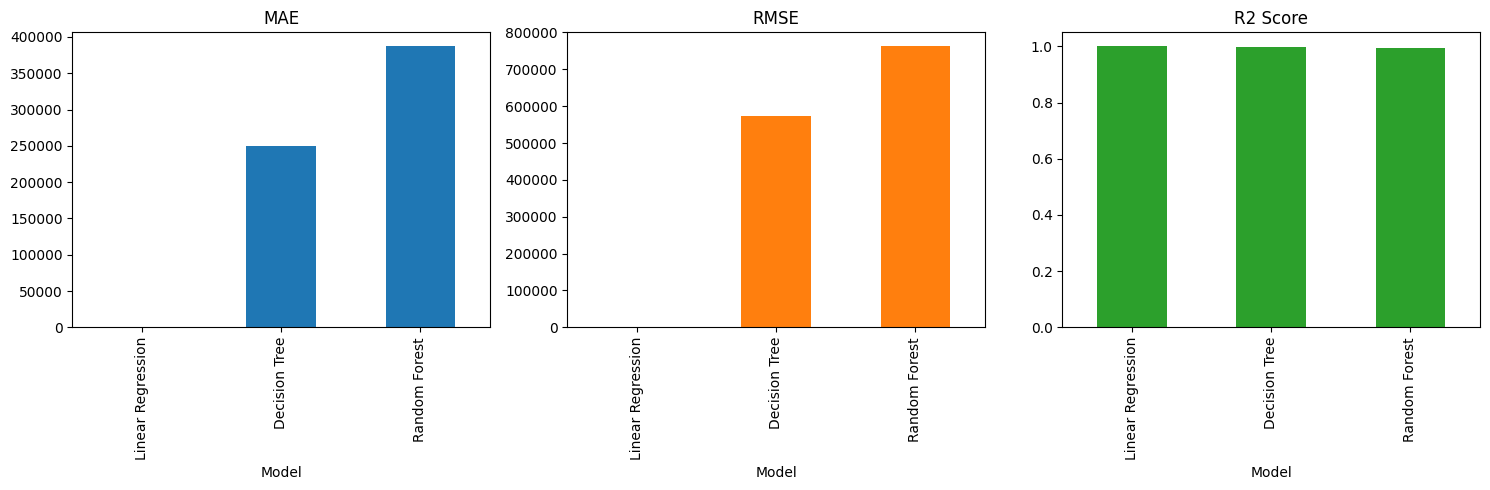

In [38]:
metrics = ["MAE", "RMSE", "R2 Score"]

comparison.set_index("Model")[metrics].plot(
    kind="bar", subplots=True, layout=(1, 3), figsize=(15, 5), legend=False
)

plt.tight_layout()
plt.show()

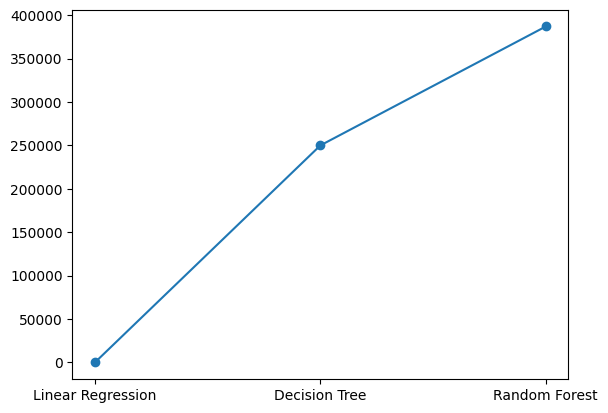

In [41]:
plt.plot(comparison["Model"], comparison["MAE"], marker="o")
plt.show()